In [1]:
%pip install scipy

Note: you may need to restart the kernel to use updated packages.


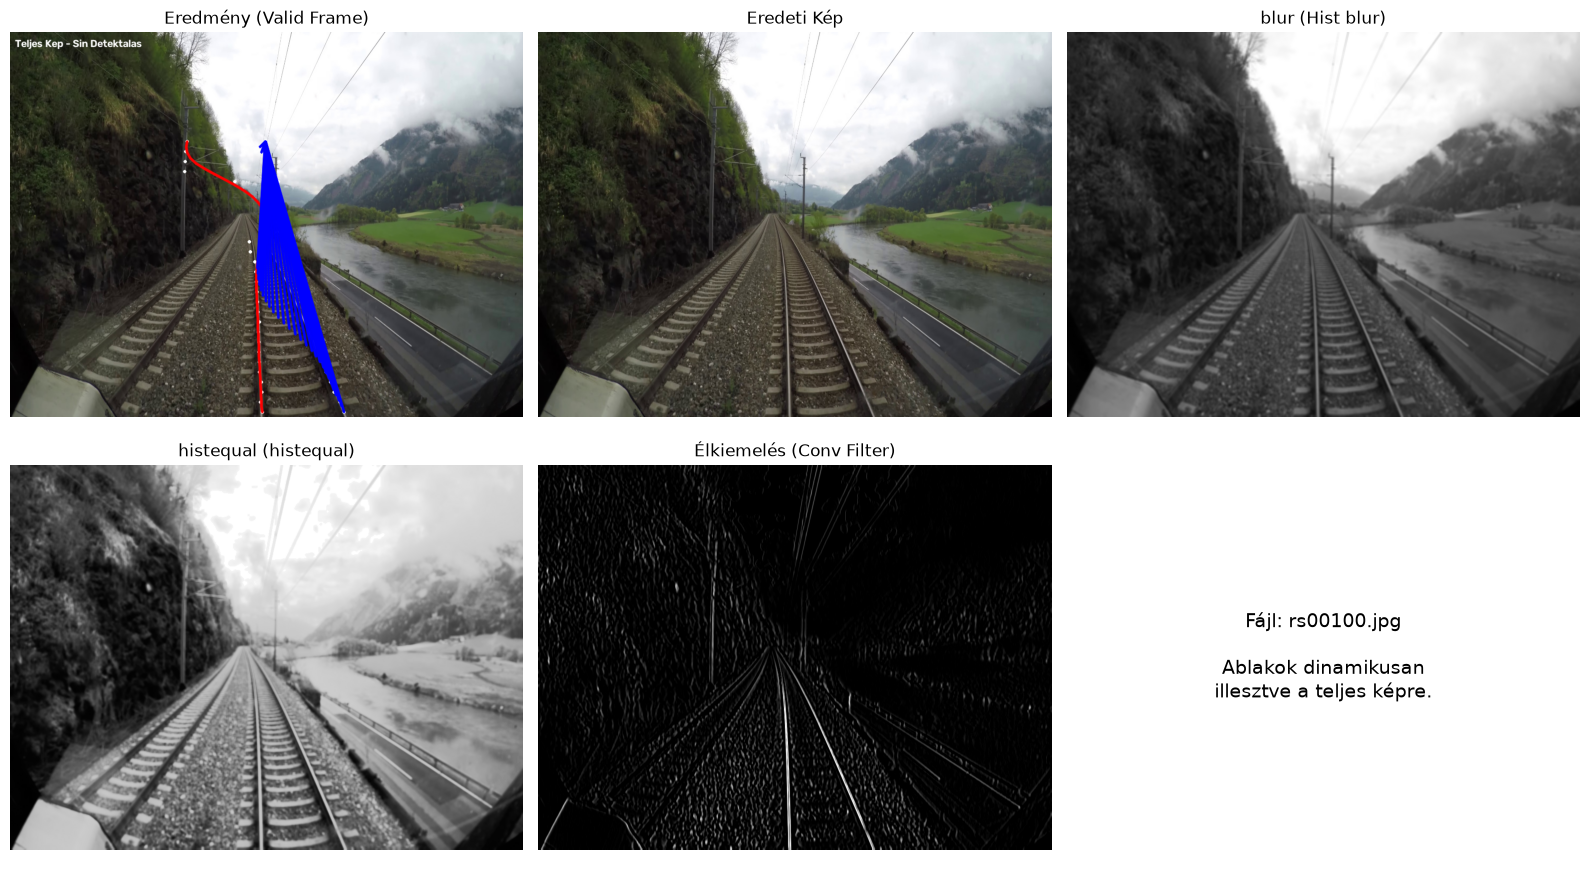

Feldolgozás befejezve.


In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output
from scipy.special import comb
import os
import time

# Mappa elérési útja
FOLDER_PATH = 'normalpics' #testpics ha az embereket akarjuk stesztelni


# --- BEZIER GÖRBE FÜGGVÉNY ---
def bezier_curve(points, ntimes=1000):
    def bernstein_poly(i, n, t):
        return comb(n, i) * (t ** (n - i)) * (1 - t) ** i

    nPoints = len(points)
    xPoints = np.array([p[0] for p in points])
    yPoints = np.array([p[1] for p in points])

    t = np.linspace(0.0, 1.0, ntimes)
    polynomial_array = np.array([bernstein_poly(i, nPoints - 1, t) for i in range(0, nPoints)])

    xvals = np.dot(xPoints, polynomial_array)
    yvals = np.dot(yPoints, polynomial_array)
    return xvals.astype('int32'), yvals.astype('int32')

# --- FŐPROGRAM ---
def main():
    valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp')
    frames_list = sorted([os.path.join(FOLDER_PATH, f) for f in os.listdir(FOLDER_PATH) if f.lower().endswith(valid_extensions)])
    
    if not frames_list:
        print(f"A '{FOLDER_PATH}' mappa üres vagy nem létezik!")
        return

    # Függőleges élkiemelő kernel
    kernel = np.array([
        [-1, 1, 0, 1, -1],
        [-1, 1, 0, 1, -1],
        [-1, 1, 0, 1, -1],
        [-1, 1, 0, 1, -1],
        [-1, 1, 0, 1, -1]
    ])

    # Kép átméretezése a feldolgozáshoz, hogy konzisztens és gyors legyen
    desired_width = 1024
    desired_height = 768

    print(f"Összesen {len(frames_list)} kép feldolgozása indul a teljes képterületen...")

    for img_path in frames_list:
        frame = cv2.imread(img_path)
        if frame is None:
            continue

        frame = cv2.resize(frame, (desired_width, desired_height))
        
        # Nincs vágás! A teljes képet használjuk.
        valid_frame = frame.copy()
        original_frame = frame.copy()

        # Képfeldolgozási lépések
        gray_frame = cv2.cvtColor(valid_frame, cv2.COLOR_BGR2GRAY)
        blur_frame = cv2.GaussianBlur(gray_frame, (5, 5), 15) #elmosás teszt 
        histeqaul_frame = cv2.equalizeHist(blur_frame)
        

        # Konvolúciós szűrő alkalmazása
        conv_frame = cv2.filter2D(histeqaul_frame, -1, kernel)

        # --- DINAMIKUS SLIDING WINDOW ---
        slide_height = 20
        slide_interval = 20
        slide_width = 100 # Keresési sáv szélessége
        
        # Kezdeti keresési ablakok: bal oldalon a bal fele, jobb oldalon a jobb fele
        sliding_window = [0, desired_width // 2, desired_width // 2, desired_width]

        left_points = []
        right_points = []

        # Lentről felfelé haladunk (a kép aljától a magasság 35%-áig, kb a horizontig)
        for i in range(desired_height - slide_height, int(desired_height * 0.25), -slide_interval):
            
            # Bal és jobb oldali szakaszok kivágása a konvolúciós képből
            left_edge = conv_frame[i:i + slide_height, sliding_window[0]:sliding_window[1]].sum(axis=0)
            right_edge = conv_frame[i:i + slide_height, sliding_window[2]:sliding_window[3]].sum(axis=0)

            # Bal sín feldolgozása
            if left_edge.max() > 0:
                left_maxindex = sliding_window[0] + left_edge.argmax()
                cv2.line(valid_frame, (left_maxindex, i + int(slide_height / 2)),
                         (left_maxindex, i + int(slide_height / 2)), (255, 255, 255), 5, cv2.LINE_AA)
                left_points.append([left_maxindex, i + int(slide_height / 2)])
                
                # Ablak szűkítése a következő lépéshez az aktuális pont körül
                sliding_window[0] = max(0, left_maxindex - slide_width)
                sliding_window[1] = min(desired_width // 2 + 50, left_maxindex + slide_width)

            # Jobb sín feldolgozása
            if right_edge.max() > 0:
                right_maxindex = sliding_window[2] + right_edge.argmax()
                cv2.line(valid_frame, (right_maxindex, i + int(slide_height / 2)),
                         (right_maxindex, i + int(slide_height / 2)), (255, 255, 255), 5, cv2.LINE_AA)
                right_points.append([right_maxindex, i + int(slide_height / 2)])
                
                # Ablak szűkítése a következő lépéshez az aktuális pont körül
                sliding_window[2] = max(desired_width // 2 - 50, right_maxindex - slide_width)
                sliding_window[3] = min(desired_width, right_maxindex + slide_width)


        # --- BEZIER GÖRBÉK RAJZOLÁSA ---
        if len(left_points) > 2:
            bezier_left_xval, bezier_left_yval = bezier_curve(left_points, 50)
            old_point = (bezier_left_xval[0], bezier_left_yval[0])
            for point in zip(bezier_left_xval, bezier_left_yval):
                cv2.line(valid_frame, old_point, point, (0, 0, 255), 3, cv2.LINE_AA) # Piros bal sín
                old_point = point

        if len(right_points) > 2:
            bezier_right_xval, bezier_right_yval = bezier_curve(right_points, 50)
            old_point = (bezier_right_xval[0], bezier_right_yval[0])
            for point in zip(bezier_right_xval, bezier_right_yval):
                cv2.line(valid_frame, old_point, point, (255, 0, 0), 3, cv2.LINE_AA) # Kék jobb sín

        cv2.putText(valid_frame, 'Teljes Kep - Sin Detektalas', (10, 30), 
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)

        # --- MEGJELENÍTÉS JUPYTERBEN (6 paneles rács) ---
        clear_output(wait=True)
        fig, axes = plt.subplots(2, 3, figsize=(16, 9))
        
        # 1. Kész sínpálya (RGB)
        axes[0, 0].imshow(cv2.cvtColor(valid_frame, cv2.COLOR_BGR2RGB))
        axes[0, 0].set_title('Eredmény (Valid Frame)')
        
        # 2. Eredeti kép (RGB)
        axes[0, 1].imshow(cv2.cvtColor(original_frame, cv2.COLOR_BGR2RGB))
        axes[0, 1].set_title('Eredeti Kép')
        
        # 3. blur Equalization (Szürke)
        axes[0, 2].imshow(blur_frame, cmap='gray')
        axes[0, 2].set_title('blur (Hist blur)')
        
        # 4. histequal
        axes[1, 0].imshow(histeqaul_frame, cmap='gray')
        axes[1, 0].set_title('histequal (histequal)')
        
        # 5. Konvolúciós szűrő
        axes[1, 1].imshow(conv_frame, cmap='gray')
        axes[1, 1].set_title('Élkiemelés (Conv Filter)')
        
        # 6. Üres/Információs panel
        axes[1, 2].text(0.5, 0.5, f'Fájl: {os.path.basename(img_path)}\n\nAblakok dinamikusan\nillesztve a teljes képre.', 
                        fontsize=14, ha='center', va='center')
        axes[1, 2].axis('off')

        for ax in axes.flatten()[:5]:
            ax.axis('off')

        plt.tight_layout()
        plt.show()
        
        # Két kép között tartunk egy kis szünetet, hogy tudd értelmezni a rácsot
        time.sleep(1.5)

    print('Feldolgozás befejezve.')

if __name__ == '__main__':
    main()